### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_JRWSKCMGEUYB


## Preparations

### Import stuff

In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from scipy import signal
import h5py
import cv2
from scipy import ndimage as ndi
from roifile import roiread
import scipy.spatial.distance as dist
import scipy.cluster.hierarchy as sch
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
import matplotlib.patches as mpatches
from sklearn.decomposition import SparsePCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

import scanpy as sc
from anndata import AnnData
import leidenalg
import igraph as ig

In [4]:
import sys
sys.path.append("../../")
from calfuncs.io import read_sync_ttl
from calfuncs.full_field_step import plot_chirp_eta, compute_qi2, plot_clustering, plot_cluster_average

In [5]:
from matplotlib import font_manager
import matplotlib as mpl
font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

### Load data

In [6]:
with pd.HDFStore("/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/leiden/result_combined.hdf5", mode='r') as store:
    E = store["E"]
    R = store["R"]

### Optimize Leiden clustering

In [7]:
def optimize_leiden_modularity(S, n_neighbors_list, resolution_list, repeats=2, metric='cosine'):
    results = []
    best_score = -1
    best_params = None

    for n_neighbors in n_neighbors_list:
        for resolution in resolution_list:
            for rep in range(repeats):
                # 1. Build graph with Scanpy
                adata = AnnData(S)
                adata.obsm['X_pca'] = S
                sc.pp.neighbors(adata, n_neighbors=n_neighbors, use_rep='X_pca', metric=metric)
                
                # 2. Extract igraph graph
                G = adata.obsp['connectivities']
                sources, targets = G.nonzero()
                weights = G.data
                edges = list(zip(sources, targets))
                g = ig.Graph(n=G.shape[0], edges=edges, edge_attrs={"weight": weights})
                
                # 3. Leiden clustering using leidenalg
                partition = leidenalg.find_partition(
                    g,
                    leidenalg.RBConfigurationVertexPartition,
                    weights=g.es["weight"],
                    resolution_parameter=resolution
                )
    
                modularity = partition.modularity
                n_clusters = len(np.unique(partition.membership))
                sc.tl.leiden(adata, resolution=resolution, flavor="igraph")
                sil_score = silhouette_score(adata.obsm["X_pca"], adata.obs["leiden"])
                results.append((n_neighbors, resolution, rep, modularity, n_clusters, sil_score))

            if modularity > best_score:
                best_score = modularity
                best_params = (n_neighbors, resolution)

    df = pd.DataFrame(results, columns=["n_neighbors", "resolution", "rep", "modularity", "n_clusters", "silhouette_score"])
    # df = df.groupby(['n_neighbors', 'resolution'])['modularity'].mean().reset_index()
    return best_params, df

### condition 1: standard scalar across columns

In [8]:
X = R[R["good"]].filter(regex="^time_").to_numpy()

# normalization
scaler = StandardScaler(with_std=False)
X_norm = scaler.fit_transform(X)

S = []
for i in range(3):
    D = X_norm[:, i * (420):(i + 1) * (420)]
    spca = SparsePCA(n_components=10, random_state=2025, alpha=3.0, tol=1e-5)
    D_spca = spca.fit_transform(D)
    S.append(D_spca)
S = np.hstack(S)

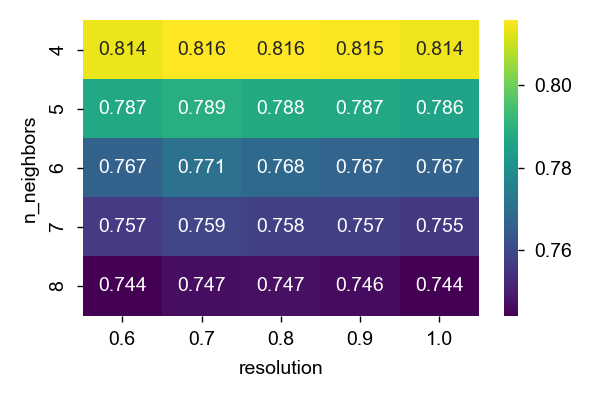

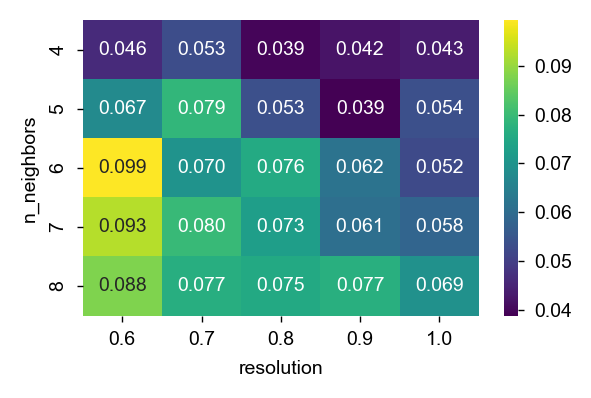

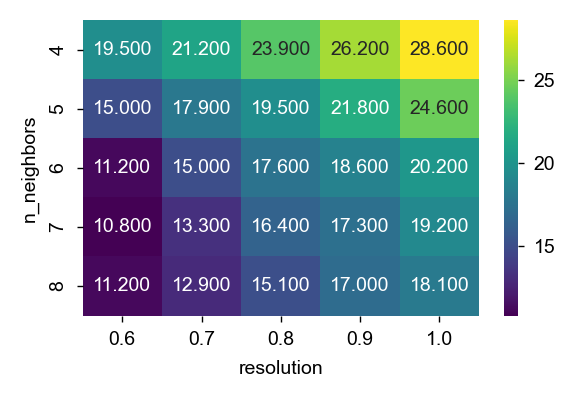

In [18]:
best_params, result_df = optimize_leiden_modularity(S, [4,5,6,7,8], [0.6,0.7,0.8,0.9,1.0], repeats=10, metric="cosine")

mat = result_df.groupby(['n_neighbors', 'resolution'])['modularity'].mean().reset_index().pivot(index='n_neighbors', columns='resolution', values='modularity')
fig, ax = plt.subplots(figsize=(3,2), dpi=200)
sns.heatmap(mat, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_xlabel("resolution")
ax.set_ylabel("n_neighbors")
plt.tight_layout()
plt.show()

mat = result_df.groupby(['n_neighbors', 'resolution'])['silhouette_score'].mean().reset_index().pivot(index='n_neighbors', columns='resolution', values='silhouette_score')
fig, ax = plt.subplots(figsize=(3,2), dpi=200)
sns.heatmap(mat, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_xlabel("resolution")
ax.set_ylabel("n_neighbors")
plt.tight_layout()
plt.show()

mat = result_df.groupby(['n_neighbors', 'resolution'])['n_clusters'].mean().reset_index().pivot(index='n_neighbors', columns='resolution', values='n_clusters')
fig, ax = plt.subplots(figsize=(3,2), dpi=200)
sns.heatmap(mat, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_xlabel("resolution")
ax.set_ylabel("n_neighbors")
plt.tight_layout()
plt.show()

19


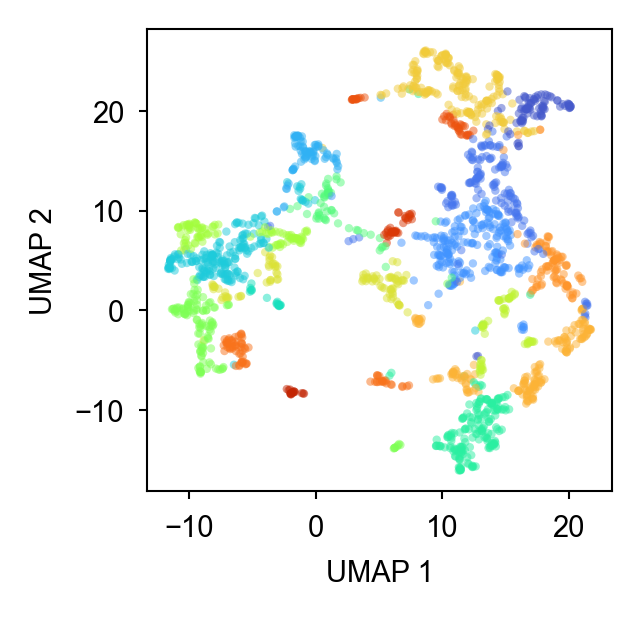

In [19]:
adata = AnnData(S)
adata.obsm['X_pca'] = S
sc.pp.neighbors(adata, n_neighbors=5, metric='cosine', use_rep='X_pca', random_state=2025)
sc.tl.leiden(adata, resolution=0.8, flavor="igraph", random_state=2025)
cluster_ids = adata.obs["leiden"].cat.codes.to_numpy().copy()
cluster_ids += 1
print(cluster_ids.max())

sc.pp.neighbors(adata, n_neighbors=5, metric='cosine', use_rep='X_pca', random_state=2025)
sc.tl.umap(adata, n_components=2, min_dist=0.1, spread=3.0)

orig_cmap = plt.get_cmap('turbo')
colors = orig_cmap(np.linspace(0.1, 0.9, 256))
new_cmap = mpl.colors.LinearSegmentedColormap.from_list('turbo_trimmed', colors, N=cluster_ids.max())
color_map = {i: new_cmap(i-1) for i in np.unique(cluster_ids)}

fig, ax = plt.subplots(figsize=(2,2), dpi=300)
X = adata.obsm['X_umap']
scatter = ax.scatter(X[:, 0], X[:, 1], c=cluster_ids, cmap=new_cmap, s=4, alpha=0.5, lw=0)
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
plt.show()

### condition 1: Robust scaler across rows, standard scalar across columns

In [ ]:
X = R[R["good"]].filter(regex="^time_").to_numpy()
scaler = RobustScaler(with_centering=True, with_scaling=True, quantile_range=(1.0, 99.0), unit_variance=True)
X_norm1 = scaler.fit_transform(X.T).T
scaler2 = StandardScaler()
X_norm = scaler2.fit_transform(X_norm1)

S = []
for i in range(3):
    D = X_norm[:, i * (420):(i + 1) * (420)]
    spca = SparsePCA(n_components=10, random_state=2025, alpha=1.0, tol=1e-5)
    D_spca = spca.fit_transform(D)
    S.append(D_spca)
S = np.hstack(S)

In [ ]:
best_params, result_df = optimize_leiden_modularity(S, [5,6,7,8,9], [0.6,0.7,0.8,0.9,1.0], repeats=10, metric="cosine")

mat = result_df.groupby(['n_neighbors', 'resolution'])['modularity'].mean().reset_index().pivot(index='n_neighbors', columns='resolution', values='modularity')
fig, ax = plt.subplots(figsize=(3,2), dpi=200)
sns.heatmap(mat, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_xlabel("resolution")
ax.set_ylabel("n_neighbors")
plt.tight_layout()
plt.show()

mat = result_df.groupby(['n_neighbors', 'resolution'])['n_clusters'].mean().reset_index().pivot(index='n_neighbors', columns='resolution', values='n_clusters')
fig, ax = plt.subplots(figsize=(3,2), dpi=200)
sns.heatmap(mat, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_xlabel("resolution")
ax.set_ylabel("n_neighbors")
plt.tight_layout()
plt.show()

In [ ]:
adata = AnnData(S)
adata.obsm['X_pca'] = S
sc.pp.neighbors(adata, n_neighbors=5, metric='cosine', use_rep='X_pca', random_state=2025)
sc.tl.leiden(adata, resolution=0.8, flavor="igraph", random_state=2025)
cluster_ids = adata.obs["leiden"].cat.codes.to_numpy().copy()
cluster_ids += 1
print(cluster_ids.max())

sc.pp.neighbors(adata, n_neighbors=6, metric='cosine', use_rep='X_pca', random_state=2025)
sc.tl.umap(adata, n_components=2, min_dist=0.2, spread=3.0)

orig_cmap = plt.get_cmap('turbo')
colors = orig_cmap(np.linspace(0.1, 0.9, 256))
new_cmap = mpl.colors.LinearSegmentedColormap.from_list('turbo_trimmed', colors, N=cluster_ids.max())
color_map = {i: new_cmap(i-1) for i in np.unique(cluster_ids)}

fig, ax = plt.subplots(figsize=(2,2), dpi=300)
X = adata.obsm['X_umap']
scatter = ax.scatter(X[:, 0], X[:, 1], c=cluster_ids, cmap=new_cmap, s=4, alpha=0.5, lw=0)
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
plt.show()

In [ ]:
best_params, result_df = optimize_leiden_modularity(S, [5,6,7,8,9], [0.6,0.7,0.8,0.9,1.0], repeats=10, metric="euclidean")

mat = result_df.groupby(['n_neighbors', 'resolution'])['modularity'].mean().reset_index().pivot(index='n_neighbors', columns='resolution', values='modularity')
fig, ax = plt.subplots(figsize=(3,2), dpi=200)
sns.heatmap(mat, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_xlabel("resolution")
ax.set_ylabel("n_neighbors")
plt.tight_layout()
plt.show()

mat = result_df.groupby(['n_neighbors', 'resolution'])['n_clusters'].mean().reset_index().pivot(index='n_neighbors', columns='resolution', values='n_clusters')
fig, ax = plt.subplots(figsize=(3,2), dpi=200)
sns.heatmap(mat, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_xlabel("resolution")
ax.set_ylabel("n_neighbors")
plt.tight_layout()
plt.show()

### condition 2: Robust scaler across rows, no scaling along columns

In [8]:
X = R[R["good"]].filter(regex="^time_").to_numpy()
scaler = RobustScaler(with_centering=True, with_scaling=True, quantile_range=(1.0, 99.0), unit_variance=True)
X_norm = scaler.fit_transform(X.T).T

S = []
for i in range(3):
    D = X_norm[:, i * (420):(i + 1) * (420)]
    spca = SparsePCA(n_components=10, random_state=2025, alpha=1.0, tol=1e-5)
    D_spca = spca.fit_transform(D)
    S.append(D_spca)
S = np.hstack(S)

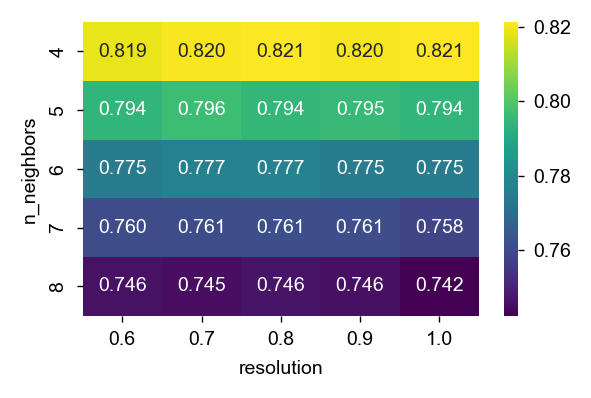

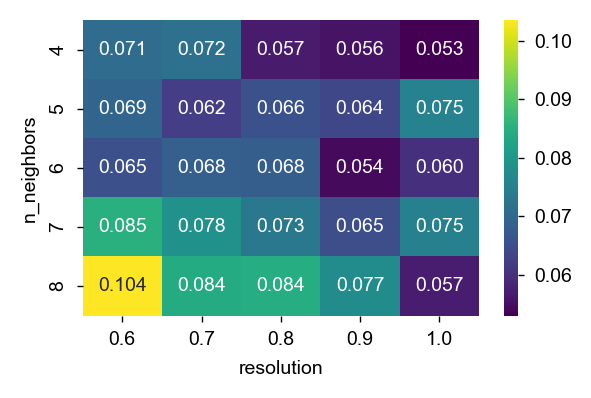

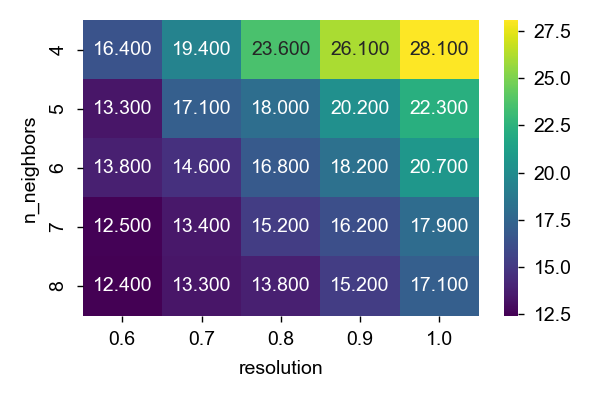

In [11]:
best_params, result_df = optimize_leiden_modularity(S, [4,5,6,7,8], [0.6,0.7,0.8,0.9,1.0], repeats=10, metric="cosine")

mat = result_df.groupby(['n_neighbors', 'resolution'])['modularity'].mean().reset_index().pivot(index='n_neighbors', columns='resolution', values='modularity')
fig, ax = plt.subplots(figsize=(3,2), dpi=200)
sns.heatmap(mat, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_xlabel("resolution")
ax.set_ylabel("n_neighbors")
plt.tight_layout()
plt.show()

mat = result_df.groupby(['n_neighbors', 'resolution'])['silhouette_score'].mean().reset_index().pivot(index='n_neighbors', columns='resolution', values='silhouette_score')
fig, ax = plt.subplots(figsize=(3,2), dpi=200)
sns.heatmap(mat, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_xlabel("resolution")
ax.set_ylabel("n_neighbors")
plt.tight_layout()
plt.show()

mat = result_df.groupby(['n_neighbors', 'resolution'])['n_clusters'].mean().reset_index().pivot(index='n_neighbors', columns='resolution', values='n_clusters')
fig, ax = plt.subplots(figsize=(3,2), dpi=200)
sns.heatmap(mat, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_xlabel("resolution")
ax.set_ylabel("n_neighbors")
plt.tight_layout()
plt.show()

24


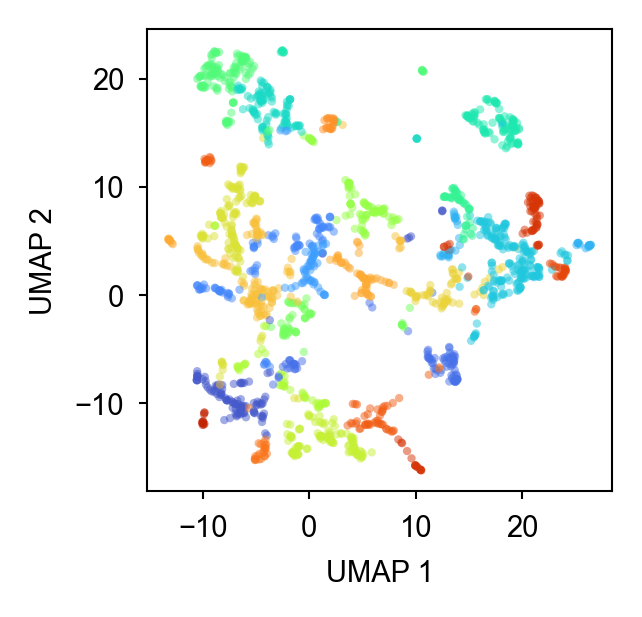

In [15]:
adata = AnnData(S)
adata.obsm['X_pca'] = S
sc.pp.neighbors(adata, n_neighbors=4, metric='cosine', use_rep='X_pca', random_state=2025)
sc.tl.leiden(adata, resolution=0.8, flavor="igraph", random_state=2025)
cluster_ids = adata.obs["leiden"].cat.codes.to_numpy().copy()
cluster_ids += 1
print(cluster_ids.max())

sc.pp.neighbors(adata, n_neighbors=4, metric='cosine', use_rep='X_pca', random_state=2025)
sc.tl.umap(adata, n_components=2, min_dist=0.05, spread=3.0)

orig_cmap = plt.get_cmap('turbo')
colors = orig_cmap(np.linspace(0.1, 0.9, 256))
new_cmap = mpl.colors.LinearSegmentedColormap.from_list('turbo_trimmed', colors, N=cluster_ids.max())
color_map = {i: new_cmap(i-1) for i in np.unique(cluster_ids)}

fig, ax = plt.subplots(figsize=(2,2), dpi=300)
X = adata.obsm['X_umap']
scatter = ax.scatter(X[:, 0], X[:, 1], c=cluster_ids, cmap=new_cmap, s=4, alpha=0.5, lw=0)
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
plt.show()

### condition 3: no scaling for rows and columns

In [41]:
X = R[R["good"]].filter(regex="^time_").to_numpy()
X_norm = X.copy()

S = []
for i in range(3):
    D = X_norm[:, i * (420):(i + 1) * (420)]
    spca = SparsePCA(n_components=10, random_state=2025, alpha=1.0, tol=1e-5)
    D_spca = spca.fit_transform(D)
    S.append(D_spca)
S = np.hstack(S)

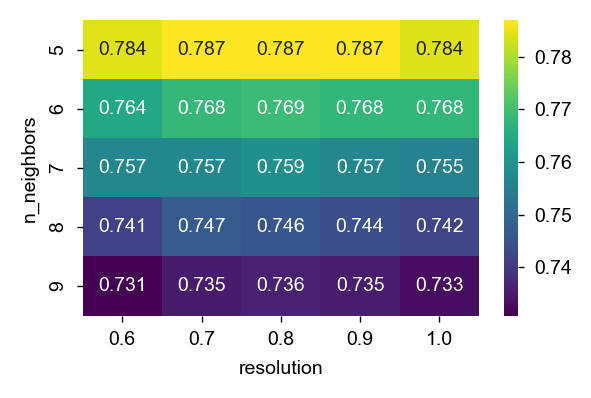

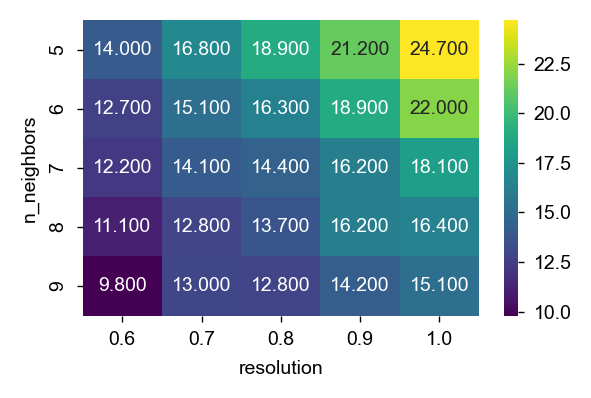

In [42]:
best_params, result_df = optimize_leiden_modularity(S, [4,5,6,7,8], [0.6,0.7,0.8,0.9,1.0], repeats=10, metric="cosine")

mat = result_df.groupby(['n_neighbors', 'resolution'])['modularity'].mean().reset_index().pivot(index='n_neighbors', columns='resolution', values='modularity')
fig, ax = plt.subplots(figsize=(3,2), dpi=200)
sns.heatmap(mat, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_xlabel("resolution")
ax.set_ylabel("n_neighbors")
plt.tight_layout()
plt.show()

mat = result_df.groupby(['n_neighbors', 'resolution'])['silhouette_score'].mean().reset_index().pivot(index='n_neighbors', columns='resolution', values='silhouette_score')
fig, ax = plt.subplots(figsize=(3,2), dpi=200)
sns.heatmap(mat, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_xlabel("resolution")
ax.set_ylabel("n_neighbors")
plt.tight_layout()
plt.show()

mat = result_df.groupby(['n_neighbors', 'resolution'])['n_clusters'].mean().reset_index().pivot(index='n_neighbors', columns='resolution', values='n_clusters')
fig, ax = plt.subplots(figsize=(3,2), dpi=200)
sns.heatmap(mat, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_xlabel("resolution")
ax.set_ylabel("n_neighbors")
plt.tight_layout()
plt.show()

21


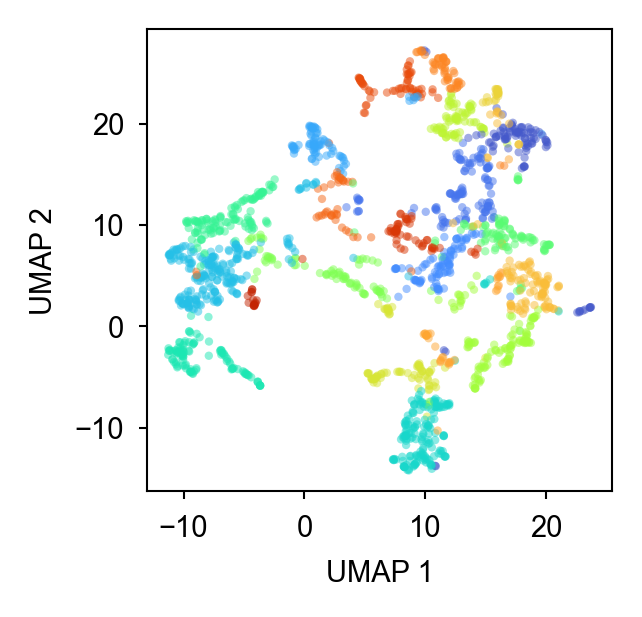

In [44]:
adata = AnnData(S)
adata.obsm['X_pca'] = S
sc.pp.neighbors(adata, n_neighbors=5, metric='cosine', use_rep='X_pca', random_state=2025)
sc.tl.leiden(adata, resolution=0.8, flavor="igraph", random_state=2025)
cluster_ids = adata.obs["leiden"].cat.codes.to_numpy().copy()
cluster_ids += 1
print(cluster_ids.max())

sc.pp.neighbors(adata, n_neighbors=5, metric='cosine', use_rep='X_pca', random_state=2025)
sc.tl.umap(adata, n_components=2, min_dist=0.1, spread=3.0)

orig_cmap = plt.get_cmap('turbo')
colors = orig_cmap(np.linspace(0.1, 0.9, 256))
new_cmap = mpl.colors.LinearSegmentedColormap.from_list('turbo_trimmed', colors, N=cluster_ids.max())
color_map = {i: new_cmap(i-1) for i in np.unique(cluster_ids)}

fig, ax = plt.subplots(figsize=(2,2), dpi=300)
X = adata.obsm['X_umap']
scatter = ax.scatter(X[:, 0], X[:, 1], c=cluster_ids, cmap=new_cmap, s=4, alpha=0.5, lw=0)
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
plt.show()

### condition 4: normalization for each session

In [8]:
X = R[R["good"]].filter(regex="^time_").to_numpy()

# normalization
X_norm = np.zeros_like(X)
for i in range(3):
    scaler = StandardScaler(with_std=False)
    x = X[:, i * (420):(i + 1) * (420)]
    X_norm[:, i * (420):(i + 1) * (420)] = scaler.fit_transform(x.T).T
scaler = StandardScaler(with_std=False)
X_norm = scaler.fit_transform(X_norm)

S = []
for i in range(3):
    D = X_norm[:, i * (420):(i + 1) * (420)]
    spca = SparsePCA(n_components=10, random_state=2025, alpha=3.0, tol=1e-5)
    D_spca = spca.fit_transform(D)
    S.append(D_spca)
S = np.hstack(S)

2025-06-06 11:16:05.593514: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1749176165.623444 3716007 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1749176165.633257 3716007 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1749176165.656455 3716007 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1749176165.656479 3716007 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1749176165.656483 3716007 computation_placer.cc:177] computation placer alr

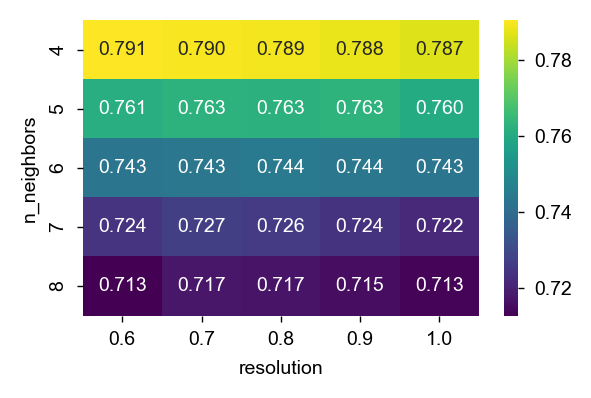

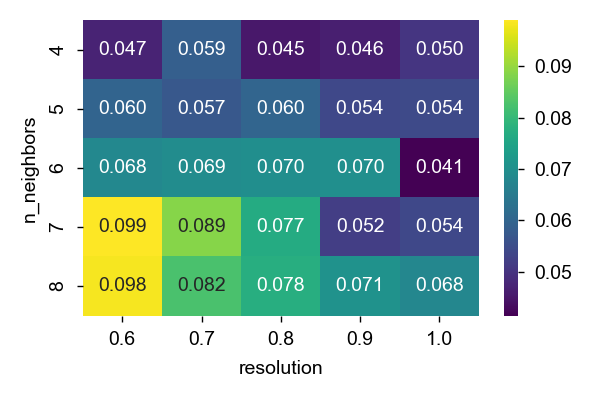

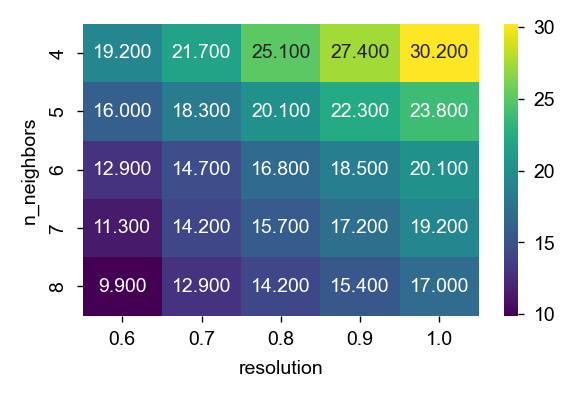

In [9]:
best_params, result_df = optimize_leiden_modularity(S, [4,5,6,7,8], [0.6,0.7,0.8,0.9,1.0], repeats=10, metric="euclidean")

mat = result_df.groupby(['n_neighbors', 'resolution'])['modularity'].mean().reset_index().pivot(index='n_neighbors', columns='resolution', values='modularity')
fig, ax = plt.subplots(figsize=(3,2), dpi=200)
sns.heatmap(mat, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_xlabel("resolution")
ax.set_ylabel("n_neighbors")
plt.tight_layout()
plt.show()

mat = result_df.groupby(['n_neighbors', 'resolution'])['silhouette_score'].mean().reset_index().pivot(index='n_neighbors', columns='resolution', values='silhouette_score')
fig, ax = plt.subplots(figsize=(3,2), dpi=200)
sns.heatmap(mat, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_xlabel("resolution")
ax.set_ylabel("n_neighbors")
plt.tight_layout()
plt.show()

mat = result_df.groupby(['n_neighbors', 'resolution'])['n_clusters'].mean().reset_index().pivot(index='n_neighbors', columns='resolution', values='n_clusters')
fig, ax = plt.subplots(figsize=(3,2), dpi=200)
sns.heatmap(mat, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_xlabel("resolution")
ax.set_ylabel("n_neighbors")
plt.tight_layout()
plt.show()

18


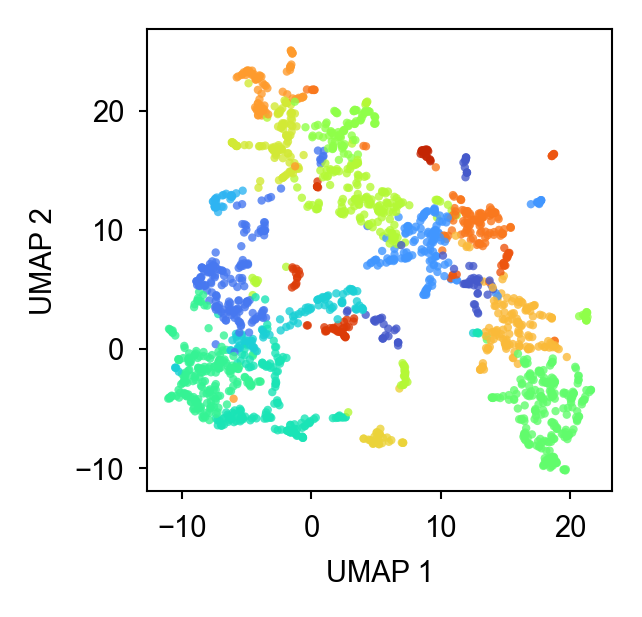

In [10]:
adata = AnnData(S)
adata.obsm['X_pca'] = S
sc.pp.neighbors(adata, n_neighbors=5, metric='euclidean', use_rep='X_pca', random_state=2025)
sc.tl.leiden(adata, resolution=0.7, flavor="igraph", random_state=2025)
cluster_ids = adata.obs["leiden"].cat.codes.to_numpy().copy()
cluster_ids += 1
print(cluster_ids.max())

# sc.pp.neighbors(adata, n_neighbors=8, metric='cosine', use_rep='X_pca', random_state=2025)
sc.tl.umap(adata, n_components=2, min_dist=0.05, spread=3.0)

orig_cmap = plt.get_cmap('turbo')
colors = orig_cmap(np.linspace(0.1, 0.9, 256))
new_cmap = mpl.colors.LinearSegmentedColormap.from_list('turbo_trimmed', colors, N=cluster_ids.max())
color_map = {i: new_cmap(i-1) for i in np.unique(cluster_ids)}

fig, ax = plt.subplots(figsize=(2,2), dpi=300)
X = adata.obsm['X_umap']
scatter = ax.scatter(X[:, 0], X[:, 1], c=cluster_ids, cmap=new_cmap, s=4, alpha=0.8, lw=0)
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
plt.show()